# Air raid alerts in Ukraine — training and validation

**Task.** For every oblast, every hour, predict

$$P(\text{the oblast is under air raid alert at some point in the next } h \text{ hours}), \qquad h \in \{1, 3, 6\}.$$

| | |
|---|---|
| forecast time | end of every hour *t* (T = t + 1 h); only information available at T is used |
| target | `y_h = 1` if any oblast- or raion-level alert is active in the oblast during hours t+1 … t+h |
| data | official alerts, **2025-11-01 → 2026-09-04 00:00 Kyiv** (raion-level alerting, before the yellow/red system) — see `eda.ipynb` |
| evaluation | rolling-origin backtest on the **last 5 weeks** before 4 Sep 2026, 4 folds, expanding and sliding training windows |
| metrics | Brier score (main), log loss, ROC AUC — pooled and per oblast |

The code lives in `ua_alerts/` (`features.py`, `models.py`, `backtest.py`, `evaluation.py`); this notebook runs and explains it.

In [1]:
import sys; sys.path.insert(0, "..")
%matplotlib inline
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
from ua_alerts import backtest, config, data, evaluation, features, models

## 1. Data and features

The hourly alert state of each oblast is turned into a panel with one row per (hour, oblast).
All features are computed from hours ≤ t:

| group | features | motivation (EDA) |
|---|---|---|
| own state | `active_now` (alert at the forecast moment), `cov_0`, `cov_1` (share of the last two hours under alert), `hours_in_alert`, `hours_quiet` | persistence dominates short-term dynamics |
| own history | rolling share under alert over 3 h / 6 h / 24 h / 7 d, alert starts in the last 1 / 6 / 24 h, same hour yesterday / last 7 days | recent level matters more than long-term averages |
| regional state | national share under alert, number of oblasts with new alerts in the last 1 / 3 h, share under alert and new alerts per macro-region (west / center / south / front) | alerts propagate between rear oblasts (onset lift 10–23×) |
| calendar | Kyiv hour of the first target hour | daily cycle with up to 7× amplitude in the rear |
| identity | `region_id` (categorical) | base rates differ from 1 % to 96 % |

Day of week and month are deliberately left out — the EDA found no evidence for them.

In [2]:
panel, indicator = backtest.load_inputs()
window = panel.loc[pd.Timestamp(config.REGIME_START):]
print(f"panel: {len(panel):,} rows (hour x oblast); modelling window: {len(window):,} rows, "
      f"{window.index.get_level_values('time').nunique():,} forecast hours x {window.index.get_level_values('region').nunique()} oblasts")
pd.DataFrame({"mean": window[features.FEATURES[:-1]].mean(), "std": window[features.FEATURES[:-1]].std()}).round(3).T

panel: 940,728 rows (hour x oblast); modelling window: 176,808 rows, 7,367 forecast hours x 24 oblasts


,active_now,cov_0,cov_1,cov_mean_3h,cov_mean_6h,cov_mean_24h,cov_mean_168h,starts_1h,starts_6h,starts_24h,hours_in_alert,hours_quiet,cov_same_hour_1d,cov_same_hour_7d,national_active,national_starts_1h,national_starts_3h,west_active,center_active,south_active,front_active,west_starts_3h,center_starts_3h,south_starts_3h,front_starts_3h,hour
mean,0.277,0.277,0.277,0.277,0.277,0.277,0.277,0.490,2.940,11.743,11.904,35.655,0.277,0.277,0.277,4.177,8.219,0.021,0.145,0.240,0.792,0.412,2.140,1.577,4.090,11.501
std,0.448,0.415,0.415,0.386,0.368,0.342,0.324,1.372,4.414,13.718,45.764,77.632,0.415,0.340,0.138,3.075,3.931,0.113,0.228,0.326,0.239,1.498,2.075,1.145,1.327,6.922


### Leakage test

The strongest guarantee against leakage is empirical: for random forecast times T, the features are rebuilt from a dataset
**truncated at T** (alerts still running at T are cut at T, nothing after T exists) and compared with the features built from the
full data. They must be identical. The test also failed as expected when a one-hour look-ahead was injected on purpose
(`cov_1 = cov.shift(-1)`), so it is able to detect leakage.

In [3]:
from tests.test_leakage import test_features_do_not_use_future_data
test_features_do_not_use_future_data()
print("leakage test passed: features at time T are identical with and without data after T")

leakage test passed: features at time T are identical with and without data after T


## 2. Validation design

* **Rolling origin.** The last 35 days before 4 Sep 2026 are split into 4 consecutive test folds (~8.75 days each). Each fold is
  forecast by models trained only on data before it.
* **Two training-window schemes.** *Expanding*: train on everything since 2025-11-01. *Sliding*: train only on the 12 weeks
  before the fold — it can adapt faster to level shifts (the EDA and a first backtest showed the west becoming quieter in August),
  at the price of less data.
* **Purging.** A training row at hour t has a target window t+1 … t+h. Rows whose target window reaches into the test fold are dropped,
  otherwise the training labels would contain test-period alerts.
* **Metrics.** Brier score is the main metric (it rewards both ranking and calibration). Log loss punishes confident mistakes.
  ROC AUC is reported **pooled** and as the **mean of per-oblast AUCs** — pooled AUC is inflated because any model that separates
  front-line oblasts (alert 95 % of the time) from the west (1–3 %) gets a high pooled AUC without forecasting anything.
  *Brier skill* = 1 − Brier(model) / Brier(hour-of-day rate).
* **Hyperparameters** are fixed in `models.py` before looking at test results; there is no tuning on the test folds.

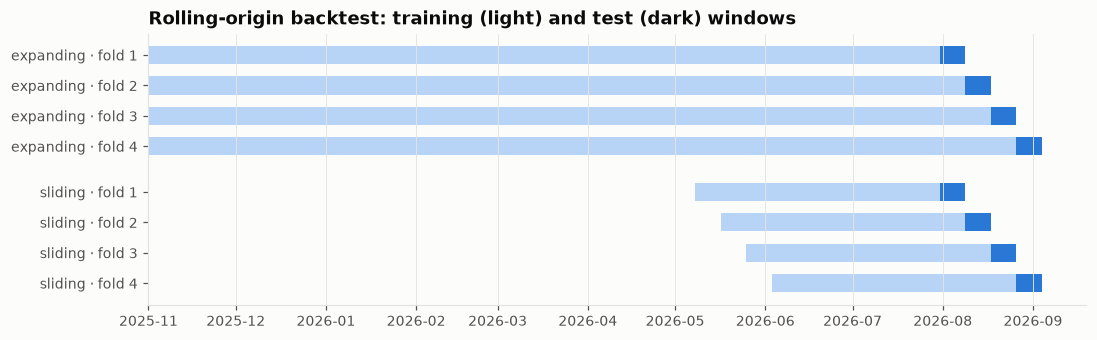

In [4]:
evaluation.plot_folds()

## 3. Models

| group | model | idea |
|---|---|---|
| baseline | **persistence** | an alert active now continues; no alert now stays quiet (naive walk without drift — drift is meaningless for a bounded 0/1 series) |
| baseline | **hour-of-day rate** | training frequency of `y_h` per oblast and Kyiv hour |
| ETS | **ETS(A,N,N), ETS(A,N,A), ETS(A,A,A), ETS(A,Ad,A)** | additive exponential smoothing of the hourly 0/1 alert indicator per oblast, seasonal period 24 h. Parameters estimated on training data; the filter then runs forward with fixed parameters, so the state at t uses only data ≤ t. The max of the 1…h-step forecasts is mapped to a probability by a **per-oblast** logistic calibration |
| ETS | **AutoETS** | per oblast, the spec with the lowest AICc on the training window. Multiplicative error/seasonality is excluded: the series contains zeros |
| statistical | **logistic AR** | logistic regression on the features above — the binary-data analogue of an autoregressive model |
| ML | **LightGBM**, **XGBoost** | gradient-boosted trees on the same features, comparable fixed hyperparameters |

ARIMA was considered and rejected: it models a continuous Gaussian quantity, can forecast outside [0, 1], forecasts the expected
share of an hour under alert rather than P(any alert within h hours), and cannot use other oblasts' state.

## 4. Training and validation run

Every model is trained and evaluated for every (window scheme, fold, horizon): 2 × 4 × 3 = 24 runs per model.
Predictions are cached in `data/processed/backtest_predictions.parquet`; `rerun=True` retrains everything.

In [5]:
preds = backtest.run_all(rerun=False)   # set rerun=True to retrain everything (~10 min)
board = backtest.leaderboard(preds)
preds.groupby(["window", "h"]).size().unstack()

h,1,3,6
window,,,
expanding,20136,20088,20016
sliding,20136,20088,20016


## 5. Results overview

Leaderboard for h = 3 h (both window schemes):

In [6]:
evaluation.leaderboard_table(board, h=3)

group     brier         brier_skill          log_loss           roc_auc         roc_auc_mean_per_oblast        
window                        expanding sliding   expanding sliding expanding sliding expanding sliding               expanding sliding
model                                                                                                                                  
XGBoost                    ML    0.0725  0.0788      0.3603  0.2886    0.2313  0.2464    0.9648  0.9607                  0.8299  0.8271
LightGBM                   ML    0.0728  0.0788      0.3571  0.2891    0.2319  0.2470    0.9646  0.9607                  0.8317  0.8197
logistic AR       statistical    0.0772  0.0797      0.3185  0.2806    0.2430  0.2489    0.9617  0.9605                  0.8373  0.8386
ETS(A,A,A)                ETS    0.0810  0.0878      0.2851  0.2074    0.2679  0.3203    0.9572  0.9458                  0.7956  0.6695
ETS(A,N,A)                ETS    0.0811  0.0880      0.2840  0.2055    0.2684  0.3211    0.9572  0.9453                  0.7955  0.6387
ETS(A,Ad,A)               ETS    0.0811  0.0880      0.2839  0.2056    0.2684  0.3211    0.9572  0.9453                  0.7954  0.6386
ETS(A,N,N)                ETS    0.0813  0.0870      0.2827  0.2151    0.2691  0.3184    0.9566  0.9460                  0.7770  0.6385
AutoETS                   ETS    0.0814  0.0870      0.2816  0.2151    0.2694  0.3184    0.9565  0.9460                  0.7797  0.6385
hour-of-day rate     baseline    0.1133  0.1108      0.0000  0.0000    0.3663  0.3954    0.9230  0.9215                  0.4766  0.5078
persistence          baseline    0.1691  0.1691     -0.4922 -0.5257    1.5576  1.5576    0.8221  0.8221                  0.7090  0.7090

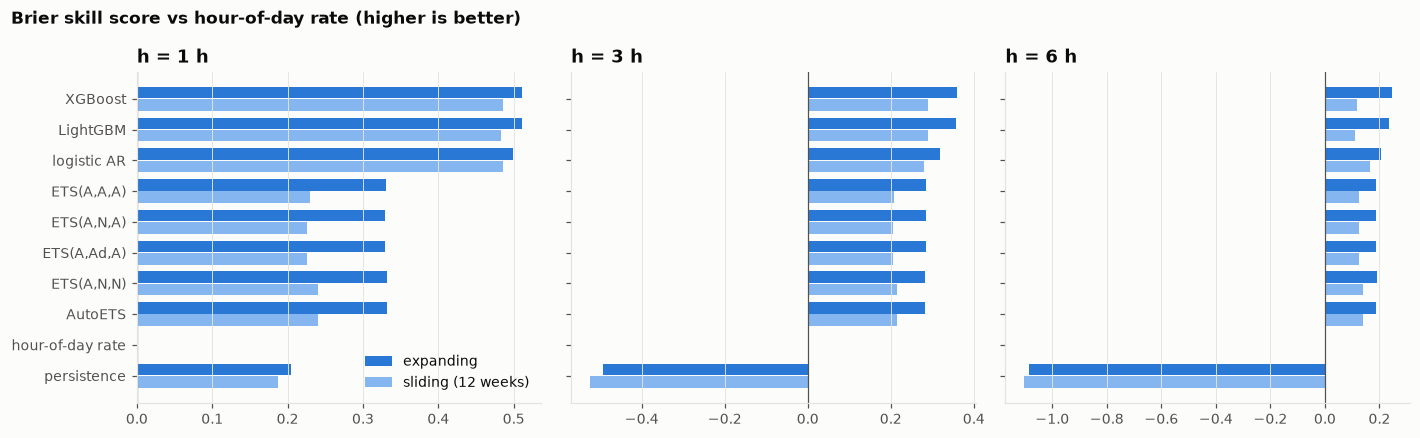

In [7]:
evaluation.plot_skill_by_horizon(board)

* **Ranking is consistent across horizons**: XGBoost ≈ LightGBM > logistic AR > ETS family > hour-of-day rate > persistence.
  At h = 3 h, XGBoost reaches a Brier score of 0.0725 (skill 0.36 vs the hour-of-day rate), LightGBM 0.0728, logistic AR 0.0772,
  the best ETS 0.081.
* **The advantage shrinks with the horizon** (skill ≈ 0.5 at 1 h, ≈ 0.36 at 3 h, ≈ 0.24 at 6 h): the current state carries most of
  the information and decays quickly.
* **Expanding beats sliding** for every trained model at every horizon, except the hour-of-day rate. More data outweighs faster adaptation; the sliding
  window helps only the climatological baseline, whose hourly profile drifts.
* **Persistence** is good at 1 h but collapses at 3–6 h, and its hard 0/1 forecasts give a very poor log loss.
* **Correction made during this analysis.** The first ETS version used a single logistic calibration pooled over all oblasts.
  The calibration plot showed it predicting ~12 % for quiet western oblasts (base rate 1 %); with per-oblast calibration the ETS
  Brier score improved from 0.087 to 0.081.

## 6. Exponential smoothing experiments

Which ETS spec does AICc choose per oblast (first training window)? ΔAICc is relative to the best spec of the oblast.

In [8]:
fold_start = backtest.folds()[0][0]
sel = evaluation.ets_selection(indicator, pd.Timestamp(config.REGIME_START).tz_convert("UTC"), fold_start - pd.Timedelta(hours=1))
print(sel["chosen"].value_counts().to_string())
sel.astype({c: float for c in sel.columns if c != "chosen"}).round(3)

chosen
A,N,N    19
A,N,A     5


,"ΔAICc A,N,N","ΔAICc A,N,A","ΔAICc A,A,A","ΔAICc A,Ad,A",chosen,alpha,gamma (seasonal)
Cherkaska oblast,0.000,253.844,265.826,259.723,"A,N,N",0.412,NaN
Chernihivska oblast,0.000,290.589,296.902,296.697,"A,N,N",0.500,NaN
Chernivetska oblast,0.000,190.522,194.558,196.577,"A,N,N",0.528,NaN
Dnipropetrovska oblast,8.321,0.000,4.036,6.056,"A,N,A",0.130,0.026
Donetska oblast,45.068,0.000,13.067,5.950,"A,N,A",0.194,0.031
Ivano-Frankivska oblast,0.000,228.089,232.125,234.144,"A,N,N",0.433,NaN
Kharkivska oblast,67.187,0.000,70.686,4.393,"A,N,A",0.137,0.033
Khersonska oblast,0.000,166.991,171.392,173.046,"A,N,N",0.417,NaN
Khmelnytska oblast,0.000,203.390,207.426,209.445,"A,N,N",0.611,NaN
Kirovohradska oblast,0.000,210.079,224.261,216.003,"A,N,N",0.391,NaN


In [9]:
ets_models = ["ETS(A,N,N)", "ETS(A,N,A)", "ETS(A,A,A)", "ETS(A,Ad,A)", "AutoETS"]
b = board[board.model.isin(ets_models)]
b.pivot_table(index="model", columns=["window", "h"], values="brier").loc[ets_models].round(4)

window      expanding                 sliding                
h                   1       3       6       1       3       6
model                                                        
ETS(A,N,N)     0.0753  0.0813  0.0879  0.0836  0.0870  0.0926
ETS(A,N,A)     0.0756  0.0811  0.0883  0.0853  0.0880  0.0942
ETS(A,A,A)     0.0754  0.0810  0.0882  0.0848  0.0878  0.0940
ETS(A,Ad,A)    0.0756  0.0811  0.0883  0.0853  0.0880  0.0942
AutoETS        0.0753  0.0814  0.0881  0.0836  0.0870  0.0926

* **AICc chooses the seasonal ETS(A,N,A) only for the five front-line oblasts** (Donetsk, Kharkiv, Sumy, Dnipropetrovsk, Zaporizhzhia),
  by large margins. For all other oblasts the 24 seasonal states are not worth their cost (ΔAICc ≈ 90–300 against seasonality).
* **A trend never helps**: the estimated trend smoothing is ≈ 0, and (A,A,A) / (A,Ad,A) are practically identical to (A,N,A).
  That is expected for a bounded 0/1 indicator.
* **Out of sample, seasonality brings no consistent gain.** In the expanding window the seasonal specs are marginally better at
  h = 3 h (Brier 0.0810 vs 0.0813 for (A,N,N)), while (A,N,N) / AutoETS are marginally better at h = 1 h and 6 h. All differences
  are ≤ 0.0005 — within noise. This matches the EDA: the daily cycle explains only a few percent of the hourly variance.
* ETS uses only the oblast's own history; that is the main reason it trails the feature-based models, which also see other oblasts.

## 7. Feature-based models: logistic AR vs LightGBM vs XGBoost

Pooled Brier score and mean per-oblast ROC AUC by horizon:

In [10]:
ml = ["logistic AR", "LightGBM", "XGBoost"]
board[board.model.isin(ml)].pivot_table(index="model", columns=["window", "h"],
                                        values=["brier", "roc_auc_mean_per_oblast"]).round(4)

brier                                         roc_auc_mean_per_oblast                                        
window      expanding                 sliding                               expanding                 sliding                
h                   1       3       6       1       3       6                       1       3       6       1       3       6
model                                                                                                                        
LightGBM       0.0551  0.0728  0.0828  0.0569  0.0788  0.0958                  0.8676  0.8317  0.7932  0.8555  0.8197  0.7487
XGBoost        0.0550  0.0725  0.0819  0.0566  0.0788  0.0948                  0.8711  0.8299  0.7937  0.8795  0.8271  0.7568
logistic AR    0.0565  0.0772  0.0862  0.0566  0.0797  0.0899                  0.8577  0.8373  0.7991  0.8645  0.8386  0.8022

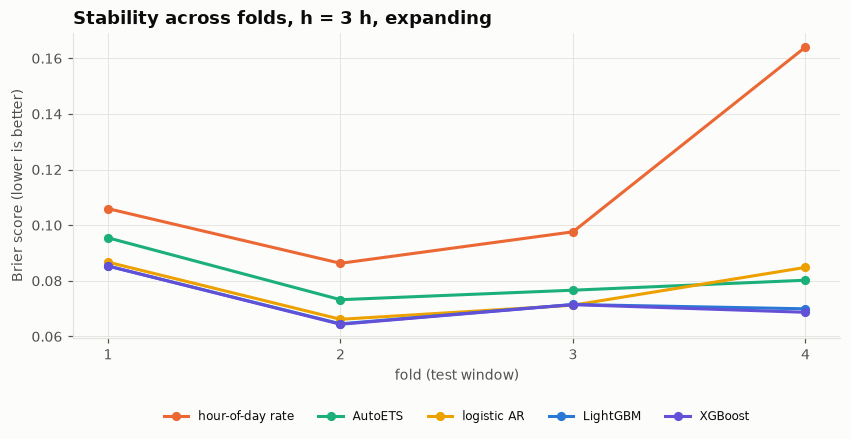

best feature-based model per (window, horizon, fold): {'logistic AR': 10, 'XGBoost': 8, 'LightGBM': 6}


In [11]:
board_folds = backtest.summarize(preds, ["window", "h", "fold"])
evaluation.plot_fold_stability(board_folds, h=3, window="expanding")
wins = board_folds[board_folds.model.isin(ml)].loc[lambda d: d.groupby(["window", "h", "fold"])["brier"].idxmin()]
print("best feature-based model per (window, horizon, fold):", wins.model.value_counts().to_dict())

In [12]:
ens = preds.assign(**{"mean of 3": preds[ml].mean(axis=1)})
eb = backtest.leaderboard(ens)
eb[(eb.window == "expanding") & eb.model.isin(ml + ["mean of 3"])].pivot_table(
    index="model", columns="h", values=["brier", "log_loss", "roc_auc_mean_per_oblast"]).round(4)

brier                 log_loss                 roc_auc_mean_per_oblast                
h                 1       3       6        1       3       6                       1       3       6
model                                                                                               
LightGBM     0.0551  0.0728  0.0828   0.1785  0.2319  0.2636                  0.8676  0.8317  0.7932
XGBoost      0.0550  0.0725  0.0819   0.1784  0.2313  0.2617                  0.8711  0.8299  0.7937
logistic AR  0.0565  0.0772  0.0862   0.1852  0.2430  0.2741                  0.8577  0.8373  0.7991
mean of 3    0.0551  0.0732  0.0827   0.1793  0.2328  0.2632                  0.8740  0.8393  0.7989

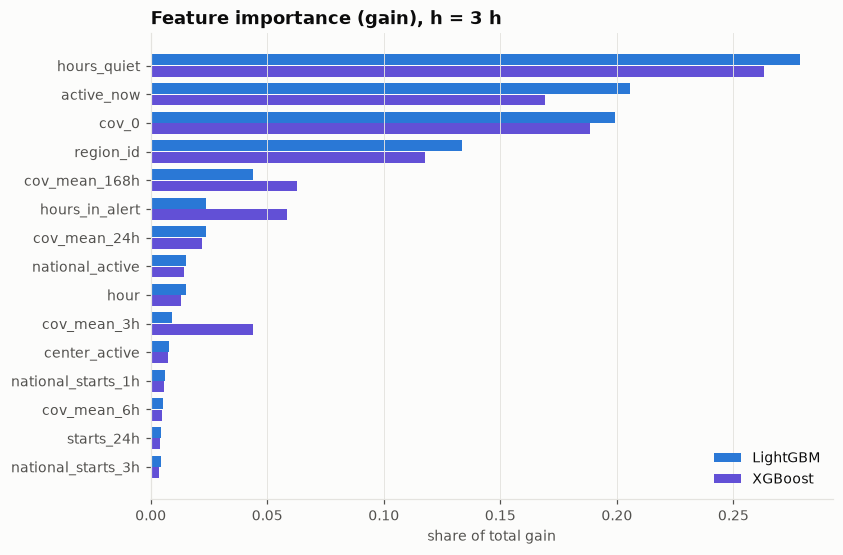

,hours_quiet,active_now,cov_0,region_id,cov_mean_168h,hours_in_alert,cov_mean_24h,national_active,hour,cov_mean_3h
LightGBM,0.279,0.206,0.199,0.133,0.044,0.024,0.024,0.015,0.015,0.009
XGBoost,0.263,0.169,0.188,0.118,0.063,0.059,0.022,0.014,0.013,0.044


In [13]:
imp = evaluation.feature_importance(panel, h=3)
evaluation.plot_feature_importance(imp, h=3)
imp.head(10).round(3).T

* **LightGBM and XGBoost are practically tied** (Brier differences ≤ 0.001 at every horizon), with XGBoost marginally ahead.
* **Logistic AR is close** — and has the *best mean per-oblast ROC AUC* at h = 3 and 6, and wins the most individual
  (window, horizon, fold) combinations. The boosters' advantage is mostly in calibration across oblasts, not in ranking within an oblast.
* **Averaging the three** gives the best per-oblast AUC at every horizon, but not the best Brier score — no clear gain, so it is
  not used as the final model.
* **Feature importance** is dominated by persistence (`hours_quiet`, `active_now`, `cov_0`) and oblast identity. Regional
  features have a small *total* gain, which is expected: they matter for rare onsets in the rear, a small share of all rows.
  Gain importance measures how often a feature splits the data, not how much it improves forecasts in the oblasts where it matters.

## 8. Per-oblast results, ROC curves and calibration

Oblasts are sorted by their test base rate (in brackets).

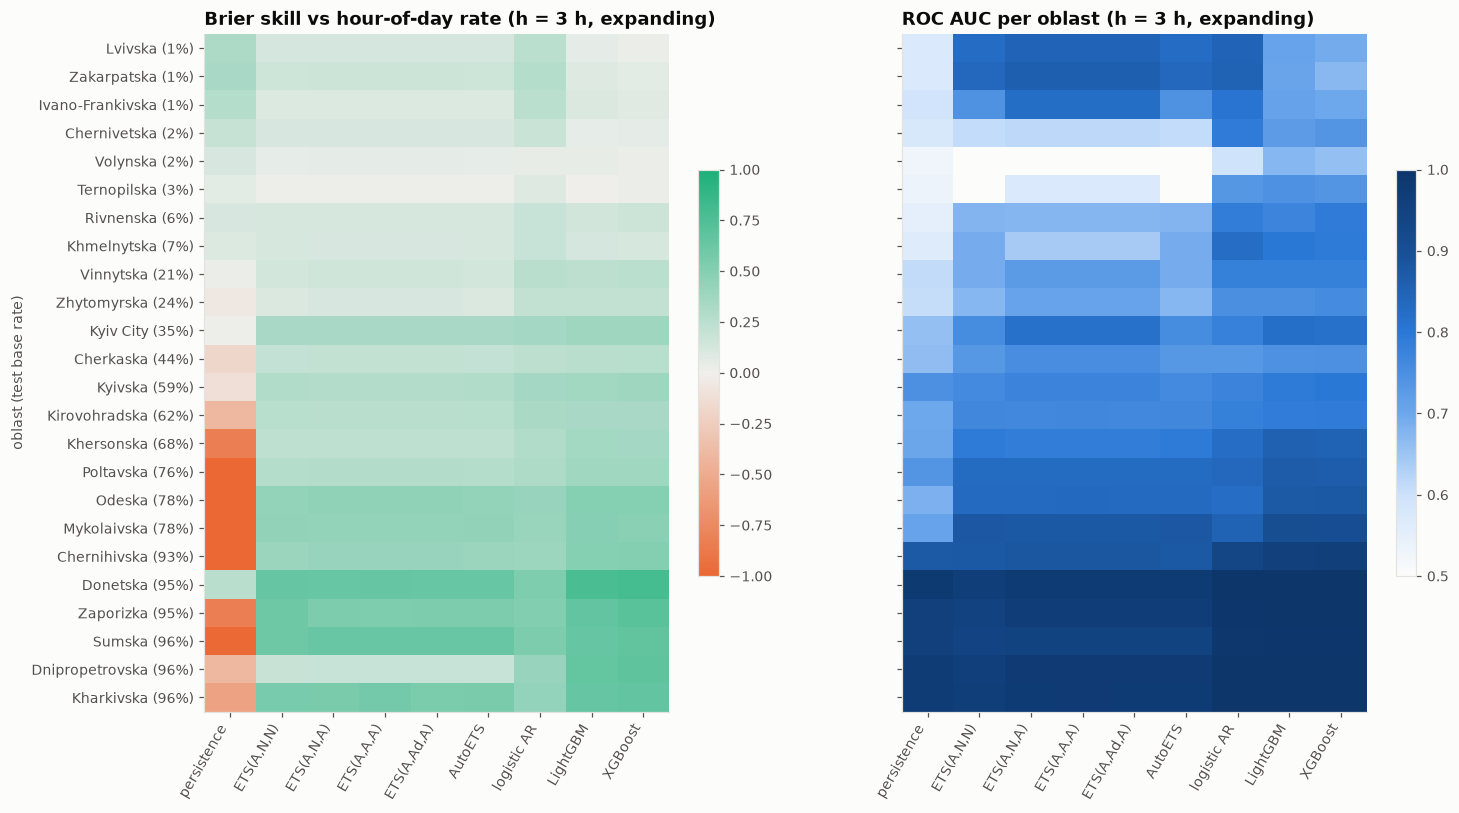

In [14]:
skill, auc = evaluation.plot_per_oblast(preds, h=3, window="expanding")

In [15]:
groups = {k: v for k, v in config.MACRO_REGIONS.items()}
best = skill.drop(columns=["persistence"]).idxmax(axis=1)
pd.DataFrame({"best model (Brier)": best,
              "skill of best": skill.drop(columns=["persistence"]).max(axis=1).round(3),
              "LightGBM AUC": auc["LightGBM"].round(3), "XGBoost AUC": auc["XGBoost"].round(3)})

,best model (Brier),skill of best,LightGBM AUC,XGBoost AUC
region,,,,
Lvivska oblast,logistic AR,0.243,0.707,0.692
Zakarpatska oblast,logistic AR,0.274,0.707,0.671
Ivano-Frankivska oblast,logistic AR,0.249,0.709,0.700
Chernivetska oblast,logistic AR,0.174,0.724,0.737
Volynska oblast,"ETS(A,A,A)",0.050,0.674,0.659
Ternopilska oblast,logistic AR,0.085,0.745,0.737
Rivnenska oblast,logistic AR,0.188,0.772,0.793
Khmelnytska oblast,logistic AR,0.193,0.800,0.794
Vinnytska oblast,logistic AR,0.256,0.782,0.782


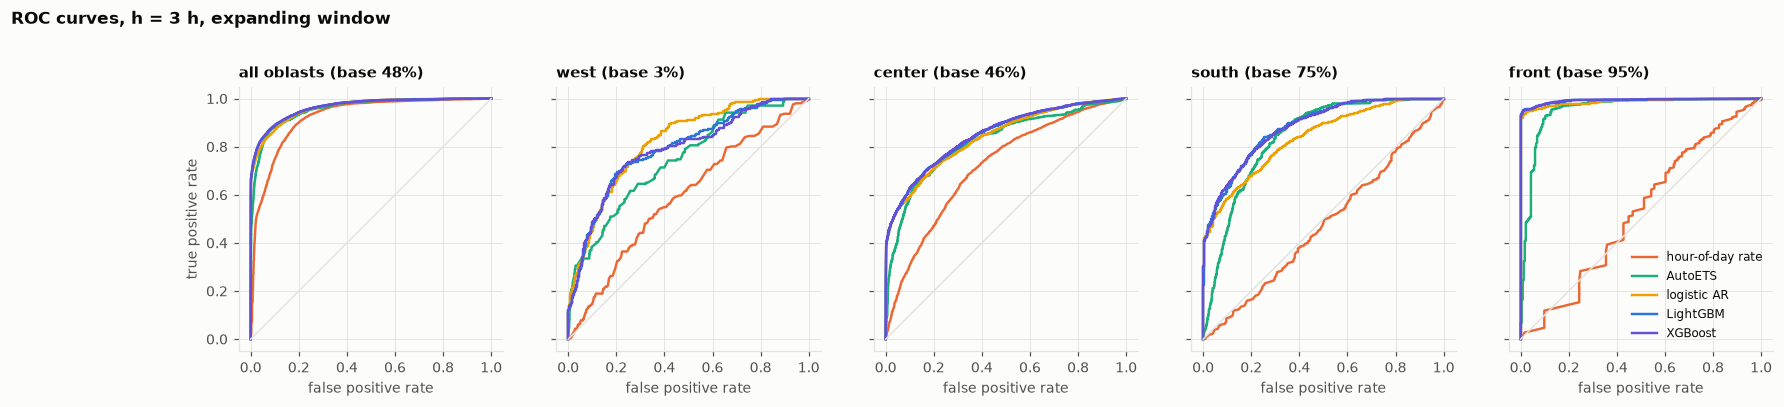

In [16]:
evaluation.plot_roc(preds, h=3, window='expanding')

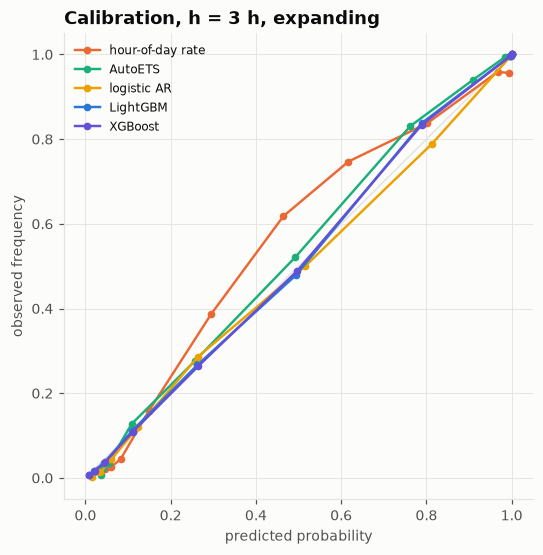

In [17]:
evaluation.plot_calibration(preds, h=3, window='expanding')

* **Middle oblasts (base rate 20–80 %)** — Kyiv, Cherkasy, Kirovohrad, Poltava, Odesa, Mykolaiv, Kherson: here alerts are genuinely
  uncertain and the boosters add the most (Brier skill 0.25–0.5, AUC 0.75–0.9).
* **West (base rate 1–7 %)**: the logistic AR is the best model in 7 of 8 western oblasts; the boosters gain little there.
  The test weeks were much quieter than training (7.1 % vs 3.1 % of hours followed by an alert within 3 h), and Lviv and
  Zakarpattia had only 7 positive hours each — model differences there are mostly noise.
* **Front line (base rate 93–96 %)**: every reasonable model is near-perfect (AUC ≈ 0.99); the remaining question is only when the rare quiet hours come.
* **The hour-of-day rate has a mean per-oblast AUC below 0.5**: the training-period hourly profile did not hold within oblasts in
  the August test weeks. The daily cycle is real on average (EDA) but not stable enough to forecast with on its own.
* **Calibration**: the feature-based models are well calibrated across the whole probability range; the hour-of-day rate is not.

## 9. Conclusions

* **Final model: XGBoost, expanding window** — best pooled Brier score and log loss at all horizons. LightGBM is an equivalent
  alternative; the logistic AR is a strong, interpretable runner-up and better in the quiet western oblasts.
* **Achieved skill** (Brier skill vs the hour-of-day rate, last 5 weeks before 4 Sep 2026): ≈ 0.5 at 1 h, 0.36 at 3 h, 0.24 at 6 h.
* **What drives the forecasts**: the oblast's current state and recent history; regional state helps for onsets in the rear;
  seasonality (daily, weekly) adds little out of sample.
* **Limitations.** The evaluation stops at 4 Sep 2026 because the alert system changed and the official data feed stopped
  (see `eda.ipynb`, section 1). Results for western oblasts rest on very few alerts. The model predicts the *official alert*, not
  the actual threat; under the yellow/red system it would have to be re-trained on new data.